In [1]:
import tensorflow as tf

In [2]:
import keras

In [3]:
from keras import layers

In [4]:
import matplotlib.pyplot as plt

In [5]:
import numpy as np 

In [6]:
(x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data()

In [7]:
print("Training images:", x_train.shape)

Training images: (60000, 28, 28)


In [8]:
print("training labels:",y_train.shape)

training labels: (60000,)


In [9]:
print("testing images:",x_test.shape)

testing images: (10000, 28, 28)


In [10]:
print("testing labels:",y_test.shape)

testing labels: (10000,)


In [11]:
x_train = x_train.astype("float32")/255.0

In [12]:
x_test = x_test.astype("float32")/255.0

In [13]:
plt.figure(figsize=(10,5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

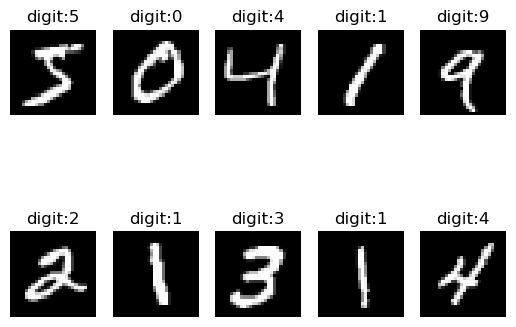

In [14]:
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap="gray")
    plt.title("digit:"+str(y_train[i]))
    plt.axis("off")
plt.show()  

In [15]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully!")

Model compiled successfully!


In [18]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.8276 - loss: 0.5751 - val_accuracy: 0.9463 - val_loss: 0.1978
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9215 - loss: 0.2662 - val_accuracy: 0.9622 - val_loss: 0.1420
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9408 - loss: 0.2015 - val_accuracy: 0.9680 - val_loss: 0.1141
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9501 - loss: 0.1685 - val_accuracy: 0.9728 - val_loss: 0.0978
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9574 - loss: 0.1426 - val_accuracy: 0.9740 - val_loss: 0.0902
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9620 - loss: 0.1268 - val_accuracy: 0.9762 - val_loss: 0.0830
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9660 - loss: 0.1134 - val_accuracy: 0.9792 - val_loss: 0.0770
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9690 - loss: 0.1018 - val_a

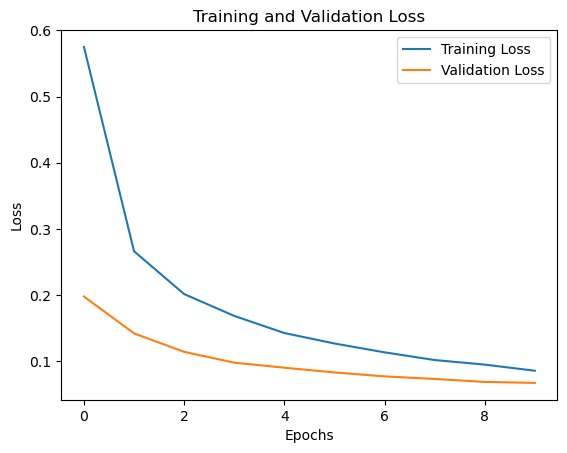

In [19]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

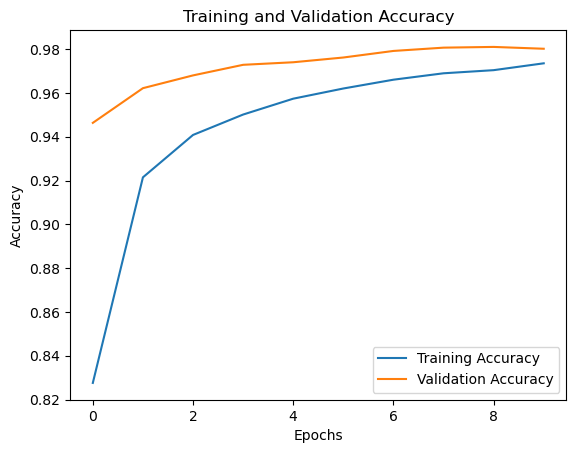

In [20]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9770 - loss: 0.0738
Test Loss: 0.07379703223705292
Test Accuracy: 97.69999980926514 %


In [22]:
predictions = model.predict(x_test[:10])

for i in range(10):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = y_test[i]

    print("Actual Digit:", actual_digit,
          "Predicted Digit:", predicted_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
Actual Digit: 7 Predicted Digit: 7
Actual Digit: 2 Predicted Digit: 2
Actual Digit: 1 Predicted Digit: 1
Actual Digit: 0 Predicted Digit: 0
Actual Digit: 4 Predicted Digit: 4
Actual Digit: 1 Predicted Digit: 1
Actual Digit: 4 Predicted Digit: 4
Actual Digit: 9 Predicted Digit: 9
Actual Digit: 5 Predicted Digit: 6
Actual Digit: 9 Predicted Digit: 9


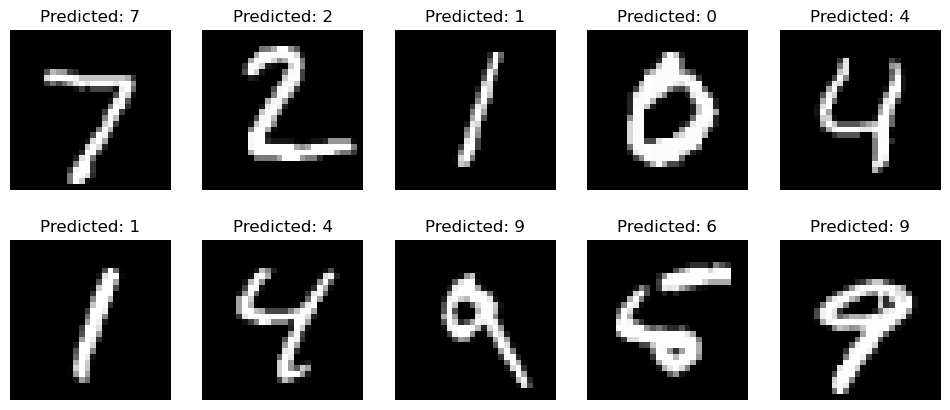

In [23]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Predicted: " + str(np.argmax(predictions[i])))
    plt.axis("off")

plt.show()

In [25]:
!pip install scikit-learn

Access is denied.


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step   


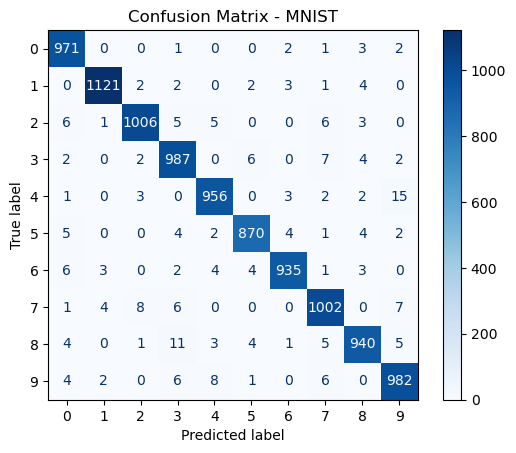

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict all testing images
y_pred = model.predict(x_test)

# Convert predicted probabilities into digit labels
y_pred = np.argmax(y_pred, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - MNIST")
plt.show()